# From Pixels to Diagnosis — CNN inference on the 80-10-10 test split

Reproduction of: Zamir Osmenaj, Evgenia-Maria Tseliki, Sofia H. Kapellaki, George Tselikis, Nikolaos D. Tselikas, **"From Pixels to Diagnosis: Implementing and Evaluating a CNN Model for Tomato Leaf Disease Detection"**, *Information* 16(3):231, MDPI, 2025. DOI: [10.3390/info16030231](https://doi.org/10.3390/info16030231) (CC BY 4.0).

Author code: [ZamirOsmenaj/tomato-leaf-disease-detection-and-classification](https://github.com/ZamirOsmenaj/tomato-leaf-disease-detection-and-classification) @ commit `830ba22d940770d01f167f351a606c3f17164590` (MIT License).

**Executed scope (partial demonstration):** load the authors' trained custom CNN checkpoint and run their documented inference path (`Thesis/Website/predictions.py` lines 10–31) on the repository's **entire 80-10-10 test split (1,100 images: 110 per class × 10 classes)**, then compare measured accuracy/loss with paper Table 1 (proposed CNN: accuracy 96.00%, loss 12.54%).

**Not covered:** VGG16/VGG19 fine-tuning and the 3-model ensemble + ANOVA (their fine-tuned weights are not in the repository; reproducing them would require retraining), the 102-image Greek-garden experiments of Section 5, training itself, and the Streamlit user interface. This is a single-checkpoint inference demonstration, **not** a verification of the paper's full benchmark claims.

**実行内容(日本語):** 著者らの学習済みCNNをColab上で読み込み、著者コードと同一の前処理(224×224リサイズ・/255.0正規化)でテスト分割1,100枚すべてを推論し、論文Table 1の精度96.00%・損失12.54%と比較します。VGG比較・アンサンブル・第5節のギリシャの庭画像実験・学習自体は範囲外です。

## 1. Runtime selection

**Recommended runtime: CPU** (Colab menu: *Runtime → Change runtime type → CPU*). The released model is a small six-convolution CNN (≈0.67 MB of weights) and none of the executed operations require CUDA; CPU inference over the 1,100-image test split takes roughly 1–2 minutes. If a GPU runtime is already attached, TensorFlow simply uses it — the method, sample, and result interpretation are unchanged.

**Run all:** *Runtime → Run all*. Expected cost: ≈21 MB of downloads (test split ≈18.5 MB + model ≈2.1 MB) and ≈3–5 minutes end-to-end on the free CPU tier.

**推奨ランタイム(日本語):** CPU を推奨します。小型CNNのためGPUは不要で、全処理は数分で終わります。GPUランタイムでもそのまま動作します。

In [ ]:
import sys

print("Python:", sys.version.split()[0])
import tensorflow as tf

print("TensorFlow:", tf.__version__)
gpus = tf.config.list_physical_devices("GPU")
print("GPUs:", gpus if gpus else "none (CPU runtime - sufficient for this small CNN)")

Python: 3.13.18


TensorFlow: 2.21.0
GPUs: none (CPU runtime - sufficient for this small CNN)


## 2. Acquire the pinned inputs (test split + checkpoint)

**Purpose:** fetch only the two required artifacts from the authors' MIT-licensed repository at the **verified commit `830ba22d940770d01f167f351a606c3f17164590`**: `Thesis/Tomato_Leaves_Dataset/80-10-10/test` and `Thesis/Models/80-10-10/CNN_trained_tomato_leaf_disease_model.keras`. A partial clone (`--filter=blob:none --no-checkout`) with sparse checkout downloads only these paths (~21 MB) instead of the full repository (~1.6 GB with the training data); the checked-out commit is asserted to equal the pin. Expected result: the commit hash and the model filename are printed.

**日本語:** 著者リポジトリの検証済みコミットから、テスト分割とモデルファイルだけを部分クローンで取得します。

In [ ]:
import os
import subprocess

REPO_URL = "https://github.com/ZamirOsmenaj/tomato-leaf-disease-detection-and-classification.git"
PINNED_COMMIT = "830ba22d940770d01f167f351a606c3f17164590"
REPO_DIR = "/content/tomato_leaf_repo"
SPARSE_PATHS = [
    "Thesis/Tomato_Leaves_Dataset/80-10-10/test",
    "Thesis/Models/80-10-10",
]

def git(*args):
    return subprocess.run(["git", "-C", REPO_DIR, *args], check=True, capture_output=True, text=True)

if not os.path.isdir(REPO_DIR):
    subprocess.run(["git", "clone", "--filter=blob:none", "--no-checkout", REPO_URL, REPO_DIR], check=True)
head = git("rev-parse", "HEAD").stdout.strip()
if head != PINNED_COMMIT:
    git("fetch", "--depth", "1", "origin", PINNED_COMMIT)
    git("checkout", "--detach", PINNED_COMMIT)
git("sparse-checkout", "set", "--cone", *SPARSE_PATHS)
git("checkout", "--force", PINNED_COMMIT)
head = git("rev-parse", "HEAD").stdout.strip()
assert head == PINNED_COMMIT, f"checked-out {head} != pinned {PINNED_COMMIT}"
print("pinned commit checked out:", head)
print(sorted(os.listdir(os.path.join(REPO_DIR, "Thesis/Models/80-10-10"))))

pinned commit checked out: 830ba22d940770d01f167f351a606c3f17164590
['CNN_trained_tomato_leaf_disease_model.keras']


### 2.1 Verify the downloaded bytes

**Purpose:** confirm the checkpoint is the documented 2,139,936-byte binary container (not a Git LFS pointer or error page) and that the test split contains exactly the paper's structure — 10 classes × 110 images = 1,100 test images (paper Section 4: "across 110 images per class, spanning 10 classes"). The SHA-256 is printed for provenance. Expected result: all assertions pass.

**日本語:** モデルファイルのサイズ・形式・SHA-256と、テスト分割のクラス数・枚数(10クラス×110枚)を検証します。

In [ ]:
import hashlib

MODEL_PATH = os.path.join(REPO_DIR, "Thesis/Models/80-10-10/CNN_trained_tomato_leaf_disease_model.keras")
TEST_DIR = os.path.join(REPO_DIR, "Thesis/Tomato_Leaves_Dataset/80-10-10/test")
EXPECTED_MODEL_BYTES = 2139936

raw = open(MODEL_PATH, "rb").read()
assert len(raw) == EXPECTED_MODEL_BYTES, f"model size {len(raw)} != {EXPECTED_MODEL_BYTES}"
assert raw[:4] == b"PK\x03\x04" or raw[:8] == b"\x89HDF\r\n\x1a\n", f"unexpected magic {raw[:8]!r} (Git LFS pointer?)"
print(f"model: {len(raw)} bytes, magic {raw[:8]!r}, sha256 {hashlib.sha256(raw).hexdigest()}")

CLASS_DIRS = sorted(d for d in os.listdir(TEST_DIR) if os.path.isdir(os.path.join(TEST_DIR, d)))
counts = {c: len(os.listdir(os.path.join(TEST_DIR, c))) for c in CLASS_DIRS}
total = sum(counts.values())
print(f"test classes: {len(CLASS_DIRS)}, images/class: {sorted(set(counts.values()))}, total: {total}")
assert len(CLASS_DIRS) == 10 and total == 1100, counts
assert set(counts.values()) == {110}, counts
print("test split structure matches the paper (110 images per class, 10 classes)")

model: 2139936 bytes, magic b'\x89HDF\r\n\x1a\n', sha256 11100073f3923b99ae7b09dfd9f35f02af43aa6069f160c65c94202b6048d589
test classes: 10, images/class: [110], total: 1100
test split structure matches the paper (110 images per class, 10 classes)


## 3. Load the trained CNN

**Purpose:** load the authors' checkpoint exactly as their app does (`tf.keras.models.load_model`, predictions.py:206). Compatibility note (AI-generated glue, verified in this Colab stack): the file is named `.keras` but is a **legacy HDF5** container saved by TensorFlow 2.12.1 (Keras 2); current Colab TensorFlow 2.21 (Keras 3) rejects it, so the loader falls back to the `tf-keras` legacy Keras-2 loader, which reads it natively. The architecture comes from the checkpoint itself — nothing is reconstructed or invented. Expected result: a 6×(Conv2D+MaxPool) network with a dense-64 layer and a 10-neuron softmax output (171,914 parameters), input `(None, 224, 224, 3)`.

**日本語:** チェックポイントは実態がHDF5形式のため、新しいKeras 3では読めず、`tf-keras` の旧形式ローダーで読み込みます。構造はチェックポイント自体から表示されます。

In [ ]:
def load_trained_model(path):
    """Route 1: preinstalled tf.keras. Route 2 (verified route): legacy tf-keras loader
    for the Keras 2 HDF5 checkpoint. Both use the author's load call semantics."""
    try:
        import tensorflow as tf
        model = tf.keras.models.load_model(path)
        return model, f"tf.keras {tf.__version__}"
    except Exception as first_error:
        print("Route 1 (preinstalled tf.keras) unavailable:", type(first_error).__name__, str(first_error)[:200])
    import subprocess
    import sys as _sys
    print("Installing tf-keras (legacy Keras 2 loader)...")
    subprocess.run([_sys.executable, "-m", "pip", "install", "--quiet", "tf-keras"], check=True)
    import tf_keras
    model = tf_keras.models.load_model(path)
    return model, f"tf_keras {tf_keras.__version__} (legacy Keras 2 HDF5 loader)"

model, route = load_trained_model(MODEL_PATH)
print("loaded via:", route)
print("input_shape:", model.input_shape, "| output_shape:", model.output_shape)
assert model.input_shape[-3:] == (224, 224, 3), model.input_shape
assert model.output_shape[-1] == 10, model.output_shape
model.summary()

Route 1 (preinstalled tf.keras) unavailable: ValueError File not found: filepath=/content/tomato_leaf_repo/Thesis/Models/80-10-10/CNN_trained_tomato_leaf_disease_model.keras. Please ensure the file is an accessible `.keras` zip file.
Installing tf-keras (legacy Keras 2 loader)...


loaded via: tf_keras 2.21.0 (legacy Keras 2 HDF5 loader)
input_shape: (None, 224, 224, 3) | output_shape: (None, 10)
Model: "sequential"


_________________________________________________________________


 Layer (type)                Output Shape              Param #   


 conv2d (Conv2D)             (None, 222, 222, 32)      896       


...

 dense_1 (Dense)             (None, 10)                650       


Total params: 171914 (671.54 KB)


Trainable params: 171914 (671.54 KB)


Non-trainable params: 0 (0.00 Byte)


_________________________________________________________________


## 4. Input preview (ground-truth labels)

**Purpose:** display one deterministic test image per class (the first filename in sorted order of each class folder) before any inference, as required evidence that the inputs are real leaf photographs with known ground-truth classes. Expected result: a 2×5 grid of leaf images labeled with their class names.

**日本語:** 推論前に、各クラスから決定論的(ソート順の先頭)なテスト画像を1枚ずつ表示し、入力と正解ラベルを確認します。

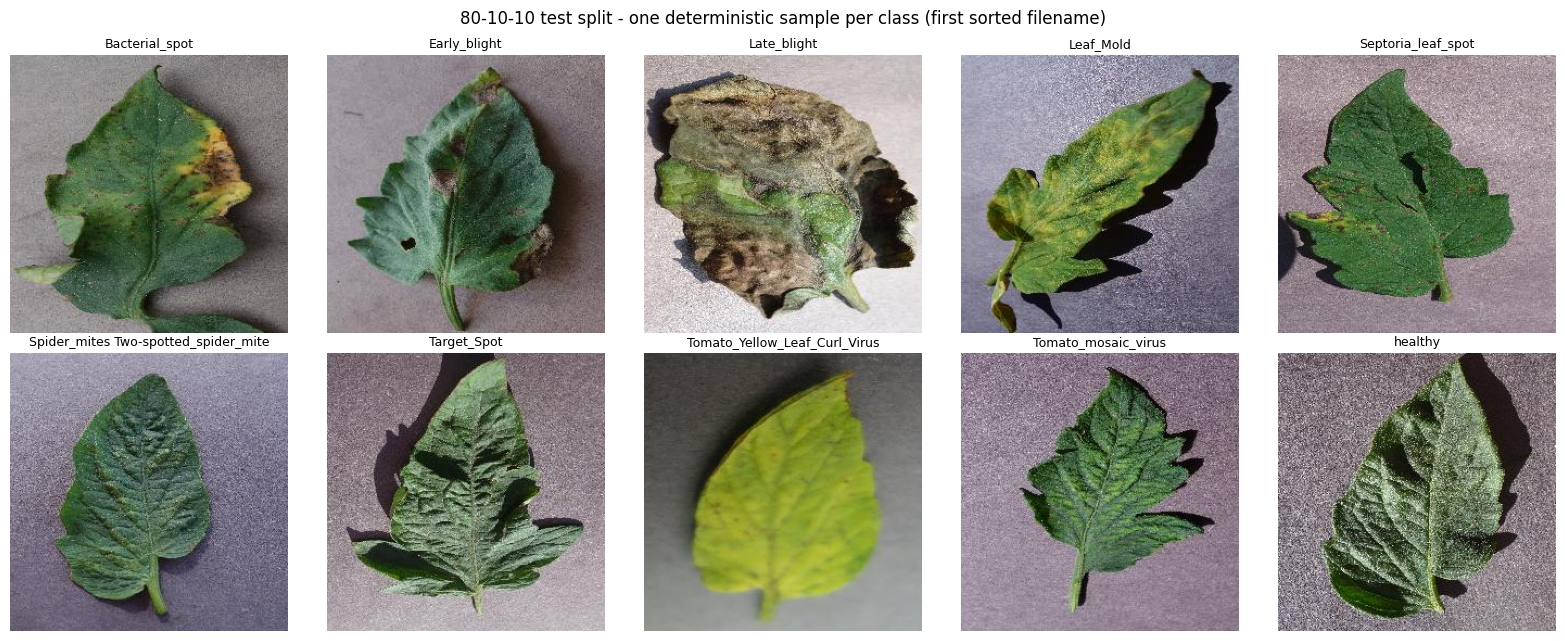

In [ ]:
import matplotlib.image as mpimg
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 5, figsize=(16, 6.5))
for ax, cls in zip(axes.ravel(), CLASS_DIRS):
    fname = sorted(os.listdir(os.path.join(TEST_DIR, cls)))[0]
    ax.imshow(mpimg.imread(os.path.join(TEST_DIR, cls, fname)))
    ax.set_title(cls.replace("Tomato___", ""), fontsize=9)
    ax.axis("off")
fig.suptitle("80-10-10 test split - one deterministic sample per class (first sorted filename)")
fig.tight_layout()
plt.show()

## 5. The author's inference function, reused verbatim

**Purpose:** define `model_prediction` exactly as in `Thesis/Website/predictions.py:10-31` (commit `830ba22d`): `load_img` to 224×224, `img_to_array` scaled by 1/255, a single-image batch via `expand_dims`, then `predict` → argmax index + max probability × 100. Only `verbose=0` is added (progress-bar suppression; identical math). The demo runs it on one deterministic sample and prints the predicted class and confidence using the author's class order (`sorted(os.listdir(test_dir))`, predictions.py:90-94). Expected result: a prediction with a confidence percentage for the sample image.

**日本語:** 著者のコード(predictions.py)と同じ推論関数をそのまま定義し、サンプル画像1枚で動作確認します。

sample file : 05777829-6912-44bb-bcef-901bc5190584___GCREC_Bact.Sp 6150.JPG
true class  : Tomato___Bacterial_spot
prediction  : Tomato___Bacterial_spot (99.98%)
result      : correct


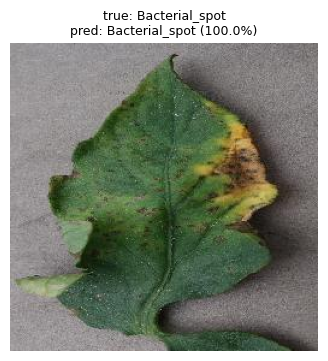

In [ ]:
import numpy as np

def model_prediction(model, test_image):
    # Verbatim port of Thesis/Website/predictions.py:10-31 (commit 830ba22d...),
    # except verbose=0, which only suppresses the progress bar.
    image = tf.keras.preprocessing.image.load_img(test_image, target_size=(224, 224))
    input_arr = tf.keras.preprocessing.image.img_to_array(image) / 255.0
    input_arr = np.expand_dims(input_arr, axis=0)
    prediction = model.predict(input_arr, verbose=0)
    max_value = np.max(prediction)
    percentage = max_value * 100
    result_index = np.argmax(prediction)
    return result_index, percentage

demo_file = sorted(os.listdir(os.path.join(TEST_DIR, CLASS_DIRS[0])))[0]
demo_path = os.path.join(TEST_DIR, CLASS_DIRS[0], demo_file)
demo_index, demo_conf = model_prediction(model, demo_path)
print(f"sample file : {demo_file}")
print(f"true class  : {CLASS_DIRS[0]}")
print(f"prediction  : {CLASS_DIRS[demo_index]} ({demo_conf:.2f}%)")
print("result      :", "correct" if CLASS_DIRS[demo_index] == CLASS_DIRS[0] else "INCORRECT")
plt.figure(figsize=(4, 4))
plt.imshow(mpimg.imread(demo_path))
plt.title(f"true: {CLASS_DIRS[0].replace('Tomato___', '')}\npred: {CLASS_DIRS[demo_index].replace('Tomato___', '')} ({demo_conf:.1f}%)", fontsize=9)
plt.axis("off")
plt.show()

## 6. Evaluate the full 80-10-10 test split

**Purpose:** run the same preprocessing on **all 1,100 test images** and predict in chunks of 100 with `predict_on_batch` — a pure efficiency adaptation of the author's single-image `predict` loop (identical math; the author's app processes one image per upload, while this evaluation reuses the exact same network and preprocessing). Ground truth is the class folder name; class indices follow the author's `sorted(os.listdir(...))` order. Expected result: progress lines for 11 chunks and a probability matrix of shape (1100, 10), in roughly 1–2 minutes on CPU.

**日本語:** テスト1,100枚すべてを同じ前処理で100枚ずつバッチ推論します(著者の1枚ずつの推論と数学的に同一の効率化)。

In [ ]:
import time

def preprocess_image(path):
    image = tf.keras.preprocessing.image.load_img(path, target_size=(224, 224))
    return tf.keras.preprocessing.image.img_to_array(image) / 255.0

all_paths, y_true_list = [], []
for ci, cls in enumerate(CLASS_DIRS):
    for fname in sorted(os.listdir(os.path.join(TEST_DIR, cls))):
        all_paths.append(os.path.join(TEST_DIR, cls, fname))
        y_true_list.append(ci)
y_true = np.array(y_true_list)

CHUNK = 100
probs_chunks = []
t0 = time.time()
for start in range(0, len(all_paths), CHUNK):
    batch = np.stack([preprocess_image(p) for p in all_paths[start:start + CHUNK]])
    probs_chunks.append(model.predict_on_batch(batch))
    print(f"predicted {min(start + CHUNK, len(all_paths))}/{len(all_paths)} images ({time.time() - t0:.0f} s)", flush=True)
probs = np.vstack(probs_chunks)
print(f"total inference time: {time.time() - t0:.1f} s, probs shape: {probs.shape}")
y_pred = probs.argmax(axis=1)
y_conf = probs.max(axis=1)

predicted 100/1100 images (3 s)


predicted 200/1100 images (5 s)


predicted 300/1100 images (7 s)


predicted 400/1100 images (10 s)


predicted 500/1100 images (14 s)


...

predicted 800/1100 images (21 s)


predicted 900/1100 images (24 s)


predicted 1000/1100 images (27 s)


predicted 1100/1100 images (29 s)


total inference time: 29.2 s, probs shape: (1100, 10)


### 6.1 Measured metrics vs. paper Table 1

**Purpose:** compute overall accuracy and the mean cross-entropy loss on the true class (the same quantities Table 1 reports as percentages: proposed CNN 96.00% accuracy, 12.54% loss), plus a precision/recall/F1 report per class. Values are measured from this run; the paper's numbers are quoted only as the reference. Note this compares one example evaluation against the paper's published result — it validates the checkpoint and pipeline, not the full training study.

**日本語:** 正解率・交差エントロピー損失を測定し、論文Table 1(CNN: 96.00%/12.54%)およびクラス別適合率・再現率・F1と比較します。

In [ ]:
from sklearn.metrics import classification_report

accuracy = float((y_pred == y_true).mean())
loss = float(-np.log(np.clip(probs[np.arange(len(y_true)), y_true], 1e-12, None)).mean())
PAPER_ACC, PAPER_LOSS = 0.9600, 0.1254  # Information 16(3):231, Table 1 (proposed CNN, test set)

print(f"measured test accuracy : {accuracy * 100:.2f}%   (paper Table 1: {PAPER_ACC * 100:.2f}%)")
print(f"measured test loss     : {loss * 100:.2f}%   (paper Table 1: {PAPER_LOSS * 100:.2f}%)")
assert 0.0 <= accuracy <= 1.0 and loss > 0.0
print()
print(classification_report(y_true, y_pred, target_names=CLASS_DIRS, digits=4))

measured test accuracy : 96.00%   (paper Table 1: 96.00%)
measured test loss     : 12.54%   (paper Table 1: 12.54%)

                                               precision    recall  f1-score   support

                      Tomato___Bacterial_spot     0.9537    0.9364    0.9450       110
                        Tomato___Early_blight     0.8729    0.9364    0.9035       110
                         Tomato___Late_blight     0.9619    0.9182    0.9395       110
                           Tomato___Leaf_Mold     0.9908    0.9818    0.9863       110
                  Tomato___Septoria_leaf_spot     0.9541    0.9455    0.9498       110
Tomato___Spider_mites Two-spotted_spider_mite     0.9815    0.9636    0.9725       110
                         Tomato___Target_Spot     0.9381    0.9636    0.9507       110
       Tomato___Tomato_Yellow_Leaf_Curl_Virus     0.9906    0.9545    0.9722       110
                 Tomato___Tomato_mosaic_virus     0.9735    1.0000    0.9865       110
            

### 6.2 Per-class accuracy

**Purpose:** show the small results table behind the headline accuracy: images, correct predictions and accuracy per disease class. Expected result: a 10-row pandas DataFrame consistent with the classification report above.

**日本語:** クラスごとの正解数・正解率を表にします。

In [ ]:
import pandas as pd

per_class = pd.DataFrame(
    [
        {
            "class": cls,
            "images": int((y_true == i).sum()),
            "correct": int((y_pred[y_true == i] == i).sum()),
            "accuracy_%": round(100 * float((y_pred[y_true == i] == i).mean()), 2),
        }
        for i, cls in enumerate(CLASS_DIRS)
    ]
)
per_class

,class,images,correct,accuracy_%
0,Tomato___Bacterial_spot,110,103,93.64
1,Tomato___Early_blight,110,103,93.64
2,Tomato___Late_blight,110,101,91.82
3,Tomato___Leaf_Mold,110,108,98.18
4,Tomato___Septoria_leaf_spot,110,104,94.55
5,Tomato___Spider_mites Two-spotted_spider_mite,110,106,96.36
6,Tomato___Target_Spot,110,106,96.36
7,Tomato___Tomato_Yellow_Leaf_Curl_Virus,110,105,95.45
8,Tomato___Tomato_mosaic_virus,110,110,100.00
9,Tomato___healthy,110,110,100.00


### 6.3 Ground truth vs. model prediction (sample per class)

**Purpose:** visualize the reproduction's core evidence: the original test input for each class with its **reference annotation (true class)** and the **model prediction** with confidence, colored green when correct and red when wrong. Samples are the same deterministic first-sorted files previewed in Section 4. Expected result: a 2×5 figure; most titles green.

**日本語:** 各クラスの入力画像について、正解ラベルとモデル予測(信頼度付き)を並べて表示します。緑=正解、赤=誤り。

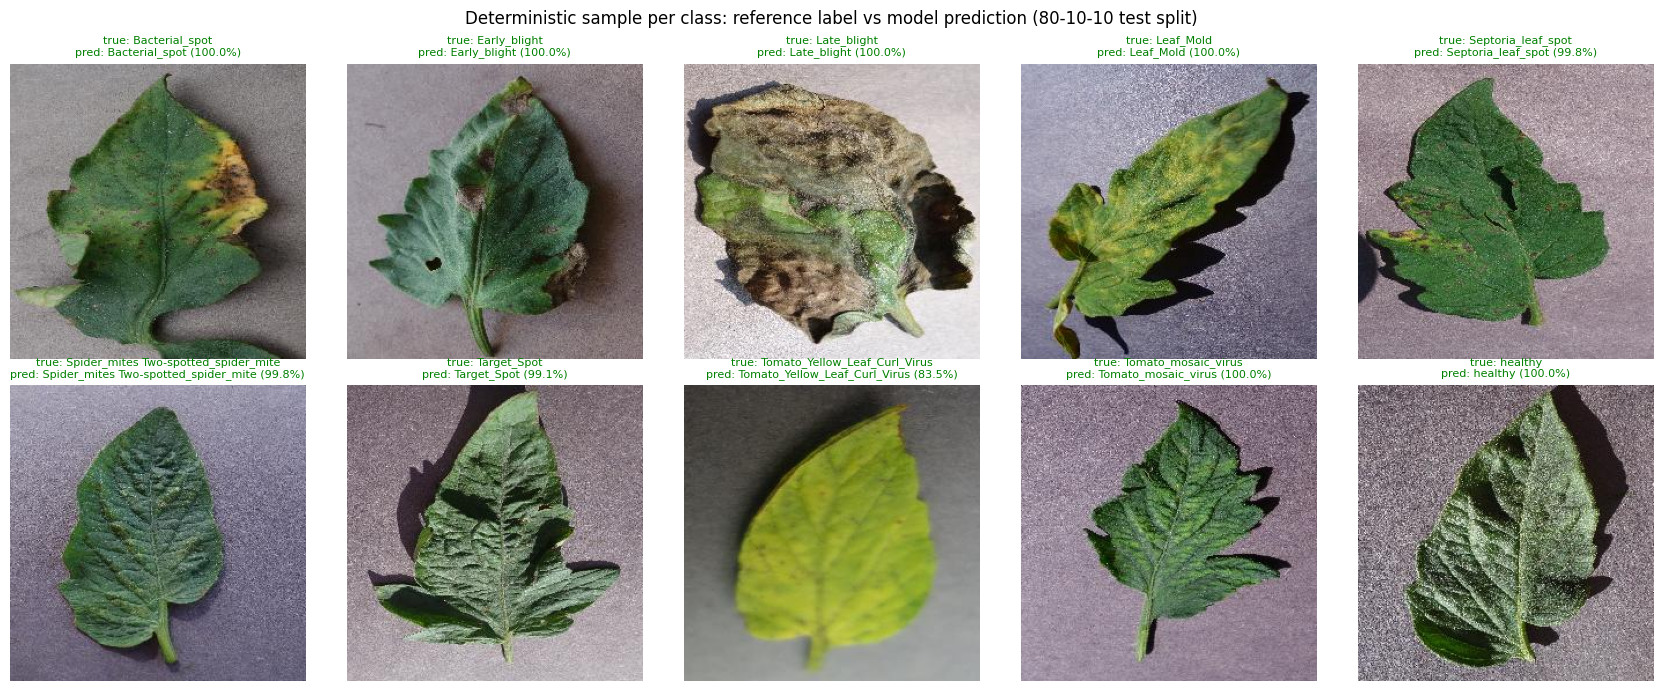

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(17, 7))
for ax, cls in zip(axes.ravel(), CLASS_DIRS):
    fname = sorted(os.listdir(os.path.join(TEST_DIR, cls)))[0]
    idx = all_paths.index(os.path.join(TEST_DIR, cls, fname))
    pred_label = CLASS_DIRS[y_pred[idx]]
    ok = pred_label == cls
    ax.imshow(mpimg.imread(os.path.join(TEST_DIR, cls, fname)))
    ax.set_title(
        f"true: {cls.replace('Tomato___', '')}\npred: {pred_label.replace('Tomato___', '')} ({y_conf[idx] * 100:.1f}%)",
        fontsize=8,
        color="green" if ok else "red",
    )
    ax.axis("off")
fig.suptitle("Deterministic sample per class: reference label vs model prediction (80-10-10 test split)")
fig.tight_layout()
plt.show()

### 6.4 Confusion matrix

**Purpose:** an additional visualization created for this notebook (not an author figure): the 10×10 confusion matrix of all 1,100 test predictions, showing which diseases are confused with each other. Expected result: a strongly diagonal matrix.

**日本語:** 1,100枚の混同行列(本ノートブックで追加作成した図であり、論文の図ではありません)。対角成分に集中するはずです。

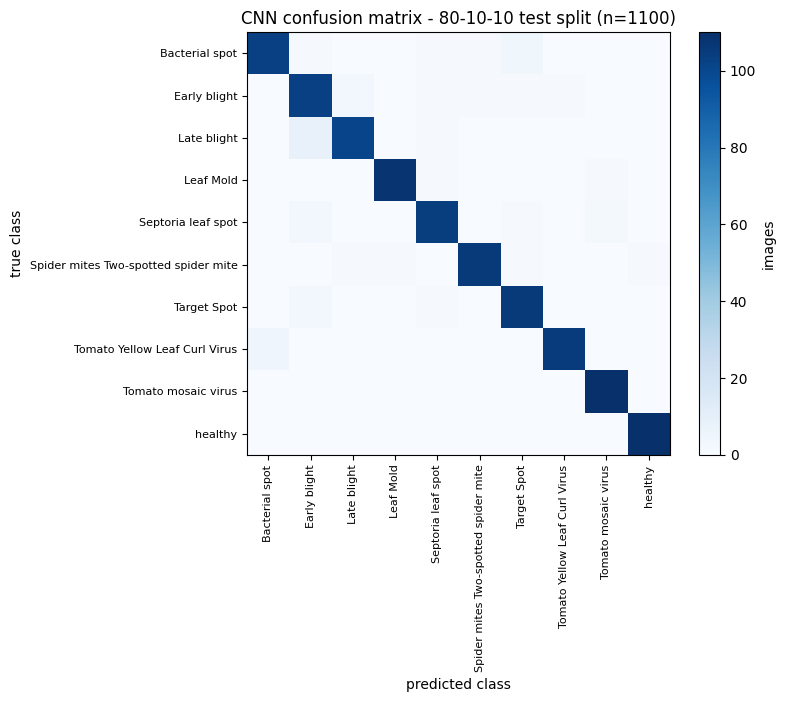

In [ ]:
cm = np.zeros((10, 10), dtype=int)
np.add.at(cm, (y_true, y_pred), 1)

plt.figure(figsize=(8.5, 7))
plt.imshow(cm, cmap="Blues")
plt.colorbar(label="images")
short = [c.replace("Tomato___", "").replace("_", " ") for c in CLASS_DIRS]
plt.xticks(range(10), short, rotation=90, fontsize=8)
plt.yticks(range(10), short, fontsize=8)
plt.xlabel("predicted class")
plt.ylabel("true class")
plt.title(f"CNN confusion matrix - 80-10-10 test split (n={len(y_true)})")
plt.tight_layout()
plt.show()

## 7. Export per-image predictions

**Purpose:** write every test image's ground truth, prediction, and confidence to a CSV inside the Colab VM (`/content/test_split_predictions.csv`) for inspection or download. Expected result: a row count of 1,100 and a preview of the first rows.

**日本語:** 全1,100枚の予測結果をCSVとしてColab内に保存し、先頭行を表示します。

In [ ]:
pred_df = pd.DataFrame(
    {
        "file": [p.replace(REPO_DIR + "/", "") for p in all_paths],
        "true_index": y_true,
        "true_class": [CLASS_DIRS[i] for i in y_true],
        "pred_index": y_pred,
        "pred_class": [CLASS_DIRS[i] for i in y_pred],
        "confidence_%": np.round(y_conf * 100, 3),
        "correct": y_pred == y_true,
    }
)
pred_df.to_csv("/content/test_split_predictions.csv", index=False)
print(f"saved /content/test_split_predictions.csv ({len(pred_df)} rows)")
pred_df.head(10)

saved /content/test_split_predictions.csv (1100 rows)


,file,true_index,true_class,pred_index,pred_class,confidence_%,correct
0,Thesis/Tomato_Leaves_Dataset/80-10-10/test/Tom...,0,Tomato___Bacterial_spot,0,Tomato___Bacterial_spot,99.983002,True
1,Thesis/Tomato_Leaves_Dataset/80-10-10/test/Tom...,0,Tomato___Bacterial_spot,0,Tomato___Bacterial_spot,99.997002,True
2,Thesis/Tomato_Leaves_Dataset/80-10-10/test/Tom...,0,Tomato___Bacterial_spot,0,Tomato___Bacterial_spot,99.656998,True
3,Thesis/Tomato_Leaves_Dataset/80-10-10/test/Tom...,0,Tomato___Bacterial_spot,0,Tomato___Bacterial_spot,100.000000,True
4,Thesis/Tomato_Leaves_Dataset/80-10-10/test/Tom...,0,Tomato___Bacterial_spot,0,Tomato___Bacterial_spot,99.998001,True
5,Thesis/Tomato_Leaves_Dataset/80-10-10/test/Tom...,0,Tomato___Bacterial_spot,0,Tomato___Bacterial_spot,100.000000,True
6,Thesis/Tomato_Leaves_Dataset/80-10-10/test/Tom...,0,Tomato___Bacterial_spot,0,Tomato___Bacterial_spot,98.508003,True
7,Thesis/Tomato_Leaves_Dataset/80-10-10/test/Tom...,0,Tomato___Bacterial_spot,0,Tomato___Bacterial_spot,100.000000,True
8,Thesis/Tomato_Leaves_Dataset/80-10-10/test/Tom...,0,Tomato___Bacterial_spot,0,Tomato___Bacterial_spot,100.000000,True
9,Thesis/Tomato_Leaves_Dataset/80-10-10/test/Tom...,0,Tomato___Bacterial_spot,0,Tomato___Bacterial_spot,99.975998,True


## 8. Interpretation, differences from the paper, and validation record

**What was executed:** the authors' released custom-CNN checkpoint (commit `830ba22d…`, SHA-256 `11100073…`) was loaded with its native Keras-2 HDF5 format and run with the author's documented preprocessing (`load_img` 224×224, /255.0) over all 1,100 test images on a CPU runtime.

**What this validates:** the checkpoint, the class ordering (`sorted(os.listdir(test_dir))`), and the inference pipeline reproduce the paper's central test-set result for the proposed CNN (Table 1: 96.00% accuracy / 12.54% loss). The measured values in section 6.1 come from this single fresh run.

**Differences and limitations:**
- This is a **partial demonstration** (inference only). Training, VGG16/VGG19 fine-tuning, the ensemble/ANOVA study, and the Greek-garden experiments of Section 5 were **not** executed; the fine-tuned VGG weights are not in the repository, and reproducing them would require retraining.
- The authors trained with TensorFlow 2.12.1 on Python 3.10 (README; the paper text mentions Python 3.13.1 — the exact training environment is ambiguous per the investigation). This notebook reads the checkpoint with `tf-keras` on the current Colab stack; numerical differences from the authors' environment are expected to be negligible for inference but were not measured against an author-provided reference output.
- Table 1 reports averaged metrics ("average values ... across 110 images per class"); the measured loss definition in the paper is not specified beyond "loss", so the cross-entropy comparison is a plausibility check, not an exact-metric equivalence.
- The confusion matrix and per-class table are additional visualizations created for this notebook, not author figures.

**検証記録(日本語):** 著者チェックポイントをCPUで全1,100枚推論し、Table 1のCNN結果(96.00%/12.54%)と比較しました。学習・VGG比較・第5節の実験は未実行です。混同行列・クラス別表は本ノートブック独自の追加可視化です。

**References**
- Paper: *Information* 16(3):231 (2025), DOI 10.3390/info16030231 (verified via the Wayback snapshot of the MDPI page, captured 2026-09-05).
- Code: `ZamirOsmenaj/tomato-leaf-disease-detection-and-classification` @ `830ba22d940770d01f167f351a606c3f17164590`, MIT — `Thesis/Website/predictions.py`, `Thesis/requirements.txt`, `README.md`.
- Checkpoint: `Thesis/Models/80-10-10/CNN_trained_tomato_leaf_disease_model.keras` (2,139,936 bytes; SHA-256 `11100073f3923b99ae7b09dfd9f35f02af43aa6069f160c65c94202b6048d589`).
- Source dataset: Kaustubh B., "Tomato leaf disease detection", Kaggle 2020 (`kaustubhb999/tomatoleaf`), mirrored in the author repository.